In [1]:
from ultralytics import YOLO
from huggingface_hub import hf_hub_download
import numpy as np
import cv2
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
import torchvision.transforms as transforms
import sqlite3

c:\Users\beach\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
model_path = "models\license_plate_keypoint.pt"

<>:1: SyntaxWarning: invalid escape sequence '\l'
<>:1: SyntaxWarning: invalid escape sequence '\l'
C:\Users\beach\AppData\Local\Temp\ipykernel_8760\676328714.py:1: SyntaxWarning: invalid escape sequence '\l'
  model_path = "models\license_plate_keypoint.pt"


In [3]:
picture = "plate.jpg"
corner_model = YOLO(model_path)

results = corner_model.predict(
    source=picture,save=True)
points = results[0].keypoints.xy[0].numpy()
src = np.ascontiguousarray(points[[0, 1, 2, 3]], dtype=np.float32)


image 1/1 i:\github project\plate-detection\plate.jpg: 512x640 1 plate, 1278.9ms
Speed: 146.9ms preprocess, 1278.9ms inference, 18.7ms postprocess per image at shape (1, 3, 512, 640)
Results saved to I:\github project\plate-detection\runs\pose\predict-4


In [4]:
dst = np.array([
    [0, 0],       # top-left
    [399, 0],     # top-right
    [399, 99],    # bottom-right
    [0, 99]       # bottom-left
], dtype=np.float32)

matrix = cv2.getPerspectiveTransform(src, dst)

straight_plate = cv2.warpPerspective(
cv2.imread(picture), matrix, (400, 100))

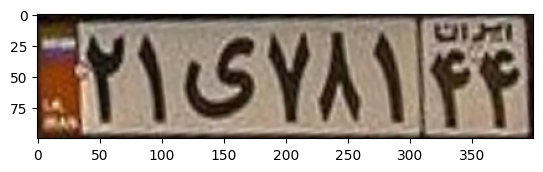

In [5]:
plt.imshow(straight_plate)

(100, 400, 3)


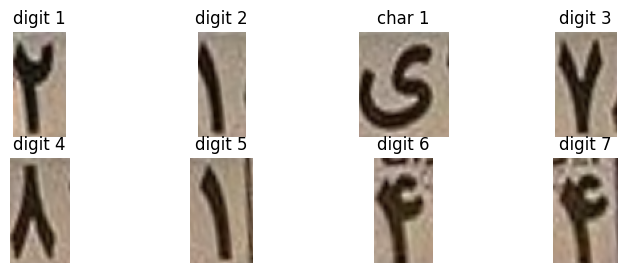

In [ ]:
h = straight_plate.shape[0]
w = straight_plate.shape[1]
print(straight_plate.shape)
plt.figure(figsize=(9, 3))
plt.subplot(2, 4, 1),plt.imshow(straight_plate[int(0.1*h):int(0.9*h),int(0.10*w):int(0.20*w)]),plt.title("digit 1"),plt.axis("off")
plt.subplot(2, 4, 2),plt.imshow(straight_plate[int(0.1*h):int(0.9*h),int(0.19*w):int(0.30*w)]),plt.title("digit 2"),plt.axis("off")
plt.subplot(2, 4, 3),plt.imshow(straight_plate[int(0.1*h):int(0.9*h),int(0.30*w):int(0.47*w)]),plt.title("char 1"),plt.axis("off")
plt.subplot(2, 4, 4),plt.imshow(straight_plate[int(0.1*h):int(0.9*h),int(0.46*w):int(0.58*w)]),plt.title("digit 3"),plt.axis("off")
plt.subplot(2, 4, 5),plt.imshow(straight_plate[int(0.1*h):int(0.9*h),int(0.55*w):int(0.68*w)]),plt.title("digit 4"),plt.axis("off")
plt.subplot(2, 4, 6),plt.imshow(straight_plate[int(0.08*h):int(0.9*h),int(0.66*w):int(0.78*w)]),plt.title("digit 5"),plt.axis("off")
plt.subplot(2, 4, 7),plt.imshow(straight_plate[int(0.18*h):int(0.9*h),int(0.79*w):int(0.89*w)]),plt.title("digit 6"),plt.axis("off")
plt.subplot(2, 4, 8),plt.imshow(straight_plate[int(0.18*h):int(0.9*h),int(0.88*w):int(0.99*w)]),plt.title("digit 7"),plt.axis("off")
plt.show()

In [ ]:
class CharacterCNN(nn.Module):
    def __init__(self, num_classes=28):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))
checkpoint = torch.load("models\persian_character_cnn.pth",
    map_location="cpu",
    weights_only=True
)
model = CharacterCNN(
    num_classes=len(checkpoint["classes"])
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

classes = checkpoint["classes"]

print("Model loaded successfully!")

Model loaded successfully!


<>:29: SyntaxWarning: invalid escape sequence '\p'
<>:29: SyntaxWarning: invalid escape sequence '\p'
C:\Users\beach\AppData\Local\Temp\ipykernel_1572\1383323646.py:29: SyntaxWarning: invalid escape sequence '\p'
  checkpoint = torch.load("models\persian_character_cnn.pth",


In [ ]:
image_path = picture

transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.Resize((32, 32)),
    transforms.ToTensor()
])

image = Image.open(image_path).convert("RGB")
image = transform(image).unsqueeze(0)

model.eval()

with torch.no_grad():
    output = model(image)
    prediction = output.argmax(dim=1).item()

print("Predicted character:", classes[prediction])

Predicted character: 2


In [ ]:
crops = [
    straight_plate[int(0.1*h):int(0.9*h), int(0.10*w):int(0.20*w)],
    straight_plate[int(0.1*h):int(0.9*h), int(0.19*w):int(0.30*w)],
    straight_plate[int(0.1*h):int(0.9*h), int(0.30*w):int(0.47*w)],
    straight_plate[int(0.1*h):int(0.9*h), int(0.46*w):int(0.58*w)],
    straight_plate[int(0.1*h):int(0.9*h), int(0.55*w):int(0.68*w)],
    straight_plate[int(0.08*h):int(0.9*h), int(0.66*w):int(0.78*w)],
    straight_plate[int(0.18*h):int(0.9*h), int(0.79*w):int(0.89*w)],
    straight_plate[int(0.18*h):int(0.9*h), int(0.88*w):int(0.99*w)]
]

In [ ]:
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((32, 32)),
    transforms.ToTensor()
])

model.eval()
predictions = []

for crop in crops:
    # OpenCV image -> PIL image
    if len(crop.shape) == 2:
        crop_rgb = crop
    else:
        crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)

    image = Image.fromarray(crop_rgb)
    x = transform(image).unsqueeze(0)

    with torch.no_grad():
        output = model(x)
        pred_idx = output.argmax(dim=1).item()

    predictions.append(classes[pred_idx])

print("Predicted characters:", predictions)

Predicted characters: ['2', '1', 'Y', '7', '8', '1', '4', '4']


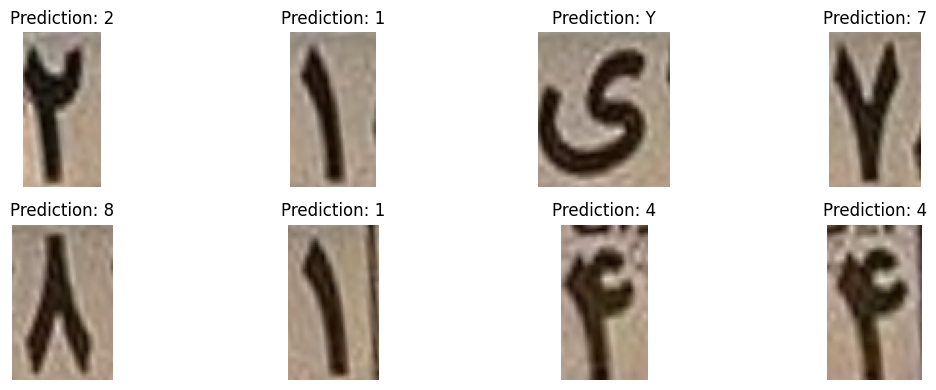

In [ ]:
plt.figure(figsize=(12, 4))

for i, (crop, pred) in enumerate(zip(crops, predictions)):
    plt.subplot(2, 4, i + 1)
    plt.imshow(crop, cmap="gray")
    plt.title(f"Prediction: {pred}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
conn = sqlite3.connect("plates2.db")
cursor = conn.cursor()

conn.execute("""
CREATE TABLE IF NOT EXISTS plates (
    id INTEGER PRIMARY KEY AUTOINCREMENT,
    digits TEXT,

    letter TEXT
)
""")

conn.commit()


In [ ]:
letter = predictions[2]

digits = "".join(
    predictions[i] for i in [0, 1, 3, 4, 5, 6, 7]
)

print(digits)  # 1234567
print(letter)  # م

2178144
Y


In [ ]:
conn.execute("""
    INSERT INTO plates (digits, letter)
    VALUES (?, ?)
""", (digits, letter))

conn.commit()
conn.close()

print("Plate saved successfully!")

Plate saved successfully!


In [ ]:
print(predictions) 

plate_letter = predictions[2]
plate_number = "".join(
    predictions[i] for i in [0, 1, 3, 4, 5, 6, 7])
print("Number:", plate_number)
print("Letter:", plate_letter)

['2', '1', 'Y', '7', '8', '1', '4', '4']
Number: 2178144
Letter: Y
